<a href="https://colab.research.google.com/github/vedikabhusari08/first_repo_vedika/blob/main/MLLAB7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vedika Bhusari C_C1_13

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from  sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [10]:
df = pd.read_csv('seeds.csv')

In [11]:
df = df.dropna(axis=1, how="all")

In [12]:
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

In [13]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1,2,3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [14]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1,2,3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [15]:
df.shape

(210, 8)

In [16]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1,2,3)'],
      dtype='object')

In [17]:
df.dtypes

,0
Area,float64
Perimeter,float64
Compactness,float64
Length of kernel,float64
Width of kernel,float64
Asymmetry coefficient,float64
Length of kernel groove,float64
"Class (1,2,3)",int64


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1,2,3)            210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [19]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1,2,3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [20]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1,2,3)",0


In [21]:
df.duplicated().sum()

np.int64(0)

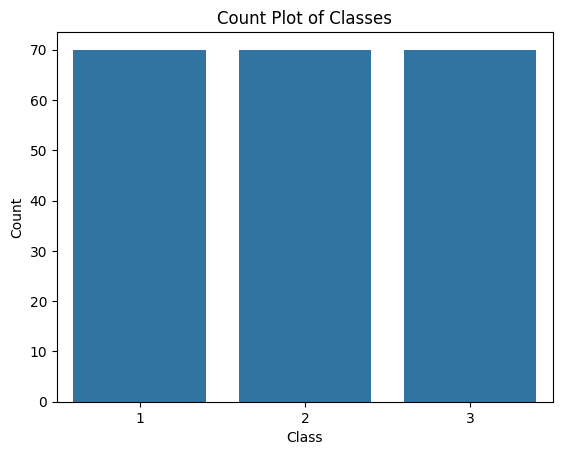

In [23]:
sns.countplot(data=df, x="Class (1,2,3)")
plt.title("Count Plot of Classes")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

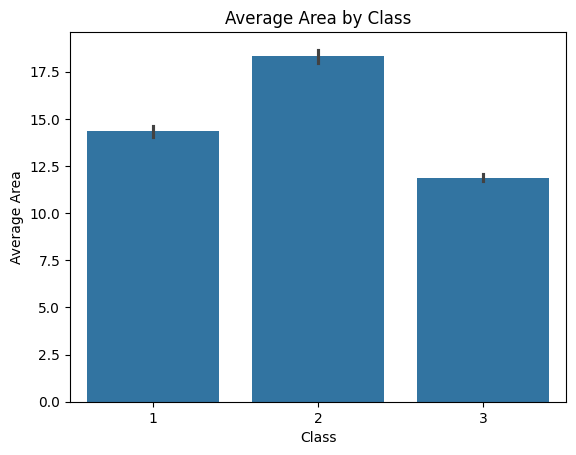

In [26]:
sns.barplot(data=df, x="Class (1,2,3)", y="Area")
plt.title("Average Area by Class")
plt.xlabel("Class")
plt.ylabel("Average Area")
plt.show()

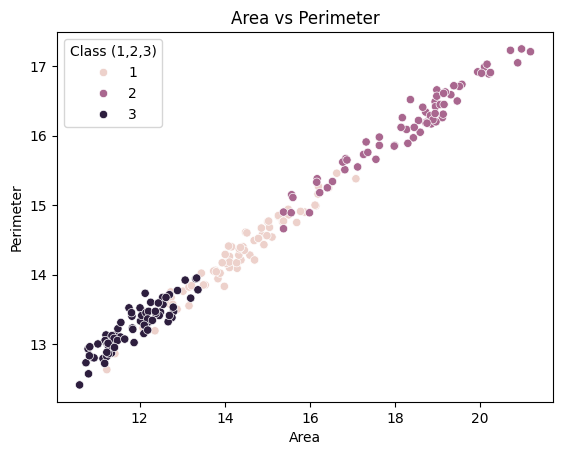

In [27]:
sns.scatterplot(
    data=df,
    x="Area",
    y="Perimeter",
    hue="Class (1,2,3)"
)
plt.title("Area vs Perimeter")
plt.show()

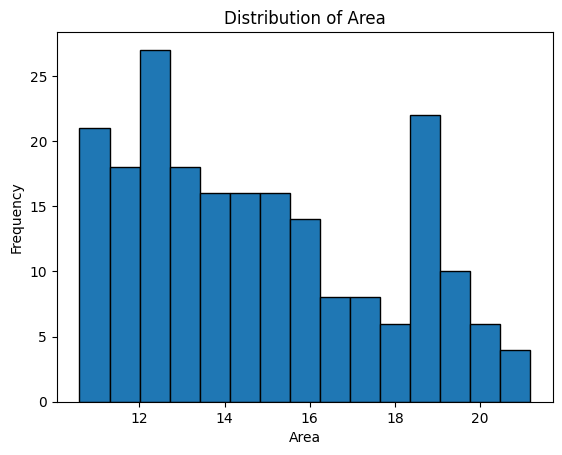

In [28]:
plt.hist(df["Area"], bins=15, edgecolor="black")
plt.title("Distribution of Area")
plt.xlabel("Area")
plt.ylabel("Frequency")
plt.show()

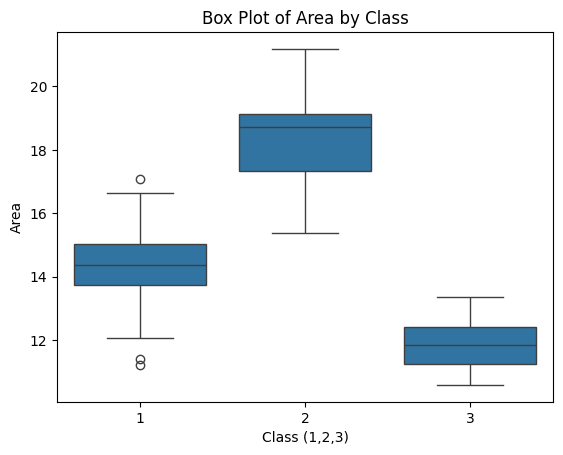

In [29]:
sns.boxplot(data=df, x="Class (1,2,3)", y="Area")
plt.title("Box Plot of Area by Class")
plt.show()

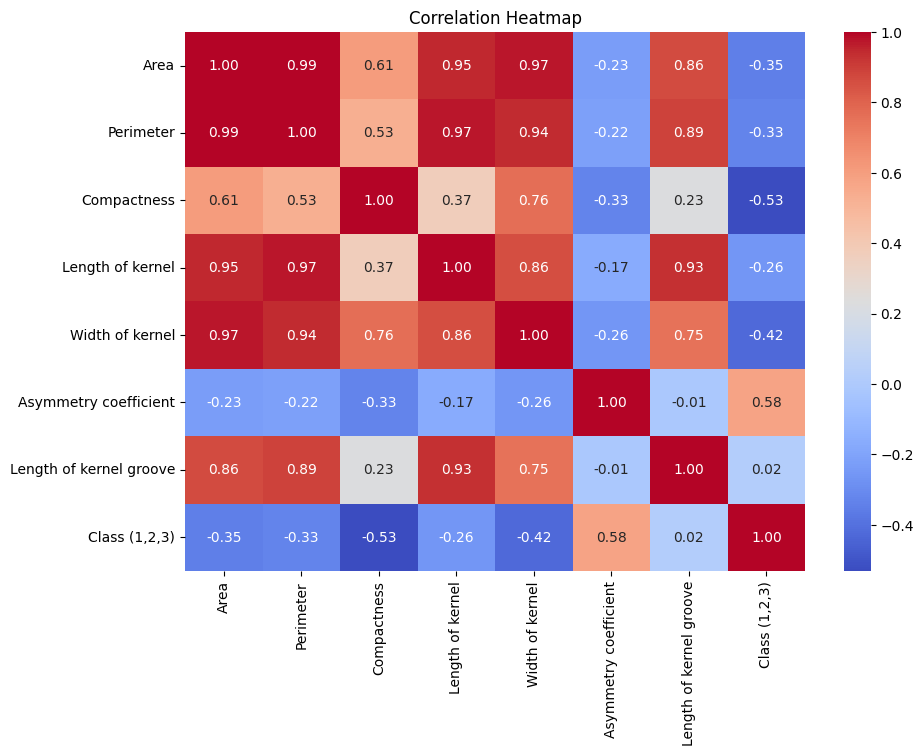

In [30]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [32]:
X = df.drop("Class (1,2,3)", axis=1)
y_original = df["Class (1,2,3)"]

In [33]:
y = y_original - 1
print("Original classes: ")
print(sorted(y_original.unique()))
print("Sortedclasses: ")
print(sorted(y.unique()))

Original classes: 
[np.int64(1), np.int64(2), np.int64(3)]
Sortedclasses: 
[np.int64(0), np.int64(1), np.int64(2)]


In [34]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 168
Testing samples: 42


In [35]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [36]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [37]:
print('First 5 scaled training examples:')
print(X_train[:5])

First 5 scaled training examples:
[[-1.17682401 -1.1750583  -1.02169157 -1.02785725 -1.35751947  1.43188942
  -0.82441016]
 [-0.87298429 -1.06714618  0.86676795 -1.26492983 -0.59897345 -0.3056117
  -1.63150367]
 [-0.12719589  0.01968295 -0.66917913  0.25096694 -0.40933695 -1.4432301
   0.1615857 ]
 [-1.29421662 -1.37546651 -0.66498255 -1.41310019 -1.26136575  1.7668294
  -0.72886004]
 [-0.58295547 -0.70486981  0.69890488 -0.90020279 -0.09149548  3.02743357
  -0.71462918]]


In [38]:
model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

In [39]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [42]:
loss = "sparse_categorical_crossentropy"

In [43]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

In [44]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose = 1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 216ms/step - accuracy: 0.5224 - loss: 0.9536 - val_accuracy: 0.7353 - val_loss: 0.8625
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.6418 - loss: 0.8799 - val_accuracy: 0.7941 - val_loss: 0.7963
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.6940 - loss: 0.8181 - val_accuracy: 0.8529 - val_loss: 0.7317
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.7164 - loss: 0.7636 - val_accuracy: 0.8529 - val_loss: 0.6755
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7463 - loss: 0.7144 - val_accuracy: 0.8824 - val_loss: 0.6228
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7537 - loss: 0.6685 - val_accuracy: 0.8824 - val_loss: 0.5768
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7761 - loss: 0.6267 - val_accuracy: 0.9118 - val_loss: 0.5404
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7985 - loss: 0.5867 - val_accuracy: 0.9118 - val_loss

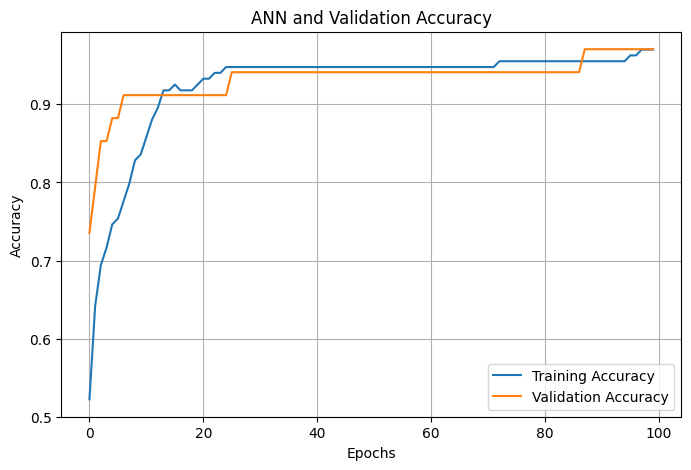

In [45]:
plt.figure(figsize = (8,5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

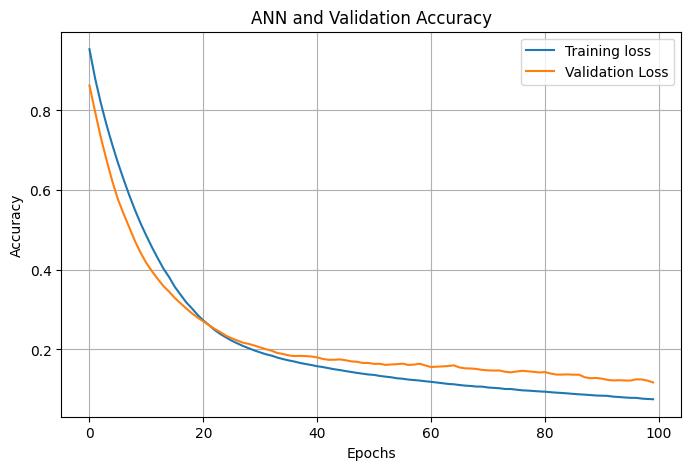

In [46]:
plt.figure(figsize = (8,5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_prob = model.predict(X_test_scaled, verbose=1)

print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
[[9.9351740e-01 4.3401862e-03 2.1424035e-03]
 [6.9590054e-02 5.2386383e-04 9.2988604e-01]
 [1.3578235e-01 8.5919362e-01 5.0240592e-03]
 [1.3444142e-03 4.1780859e-06 9.9865144e-01]
 [1.3456015e-03 9.9865299e-01 1.4816136e-06]]


In [48]:
y_prob = model.predict(X_test_scaled, verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
[[9.9351740e-01 4.3401862e-03 2.1424035e-03]
 [6.9590054e-02 5.2386383e-04 9.2988604e-01]
 [1.3578235e-01 8.5919362e-01 5.0240592e-03]
 [1.3444142e-03 4.1780859e-06 9.9865144e-01]
 [1.3456015e-03 9.9865299e-01 1.4816136e-06]]


In [49]:
y_pred = np.argmax(y_prob, axis = 1)
print("Predicted encoded classes: ")
print(y_pred[:10])

Predicted encoded classes: 
[0 2 1 2 1 2 1 1 1 1]


In [50]:
y_pred_original = y_pred + 1
y_test_original = y_test + 1

print("Predicted Classes: ")
print(y_pred_original[:10])

Predicted Classes: 
[1 3 2 3 2 3 2 2 2 2]


In [51]:
comparison = pd.DataFrame({
    "Actual Class": y_test_original,
    "Predicted Class": y_pred_original
})
comparison.head(15)

,Actual Class,Predicted Class
2,1,1
167,3,3
137,2,2
175,3,3
130,2,2
141,3,3
114,2,2
51,1,2
84,2,2
110,2,2


In [52]:
accuracy = accuracy_score(y_test_original, y_pred_original)
print("Accuracy:", accuracy)

Accuracy: 0.8571428571428571


In [53]:
precision_score = precision_score(y_test_original, y_pred_original, average="weighted")
print("Precision Score:", precision_score)

Precision Score: 0.8823529411764707


In [54]:
recall = recall_score(y_test_original, y_pred_original, average="weighted")
print("Recall:", recall)

Recall: 0.8571428571428571


In [55]:
f1 = f1_score(y_test_original, y_pred_original, average="weighted")
print("F1 Score:", f1)

F1 Score: 0.8445747800586509


In [56]:
classification_rep = classification_report(y_test_original, y_pred_original)
print("Classification Report:")
print(classification_rep)

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.57      0.73        14
           2       0.82      1.00      0.90        14
           3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.88      0.86      0.84        42
weighted avg       0.88      0.86      0.84        42



In [57]:
cm = confusion_matrix(y_test_original, y_pred_original)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 8  3  3]
 [ 0 14  0]
 [ 0  0 14]]
